# 🛟 Lifeboat Ledger: Who Survived the Titanic, and Why?

**Prodigy InfoTech Data Science Internship – Task 02** · Vaishnav Kumbhar ([@VaishnavK9](https://github.com/VaishnavK9))

> **Task:** Perform data cleaning and exploratory data analysis (EDA) on the Titanic dataset. Explore the relationships between variables and identify patterns and trends in the data.

This notebook tells the story as a sequence of **Question → Chart → Insight** steps. All the logic lives in `src/`, and this notebook just runs it in order:

| Step | Module |
|---|---|
| Load & inspect | `src/data_loader.py` |
| Clean | `src/cleaning.py` |
| Engineer features | `src/features.py` |
| Charts & statistical tests | `src/eda.py` |
| Baseline models | `src/model_baseline.py` |

Every chart is also saved to `reports/figures/`.

In [1]:
%matplotlib inline
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
from IPython.display import display

from src import data_loader, cleaning, features, eda, model_baseline

pd.set_option("display.max_columns", 30, "display.width", 160, "display.max_colwidth", 90)
eda.set_style()

## 1. First look at the data

Three files from the [Prodigy InfoTech dataset repo](https://github.com/Prodigy-InfoTech/data-science-datasets/tree/main/Task%202):
`train.csv` (891 labelled passengers), `test.csv` (418 unlabelled) and `gender_submission.csv` (Kaggle's "all women survive" example).

In [2]:
raw = data_loader.load_all()
for name, df in raw.items():
    report = data_loader.inspect_dataframe(df, name)
    print(f"{name:<18} shape={report.shape}  duplicate rows={report.duplicate_rows}  duplicate IDs={report.duplicate_ids}")
raw["train"].head()

train              shape=(891, 12)  duplicate rows=0  duplicate IDs=0
test               shape=(418, 11)  duplicate rows=0  duplicate IDs=0
gender_submission  shape=(418, 2)  duplicate rows=0  duplicate IDs=0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
data_loader.inspect_dataframe(raw["train"], "train").columns

,dtype,non_null,nulls,null_%,unique
PassengerId,int64,891,0,0.0,891
Survived,int64,891,0,0.0,2
Pclass,int64,891,0,0.0,3
Name,str,891,0,0.0,891
Sex,str,891,0,0.0,2
Age,float64,714,177,19.9,88
SibSp,int64,891,0,0.0,7
Parch,int64,891,0,0.0,7
Ticket,str,891,0,0.0,681
Fare,float64,891,0,0.0,248


In [4]:
data_loader.missing_summary({"train": raw["train"], "test": raw["test"]})

,train_nulls,train_%,test_nulls,test_%
Age,177,19.9,86,20.6
Fare,0,0.0,1,0.2
Cabin,687,77.1,327,78.2
Embarked,2,0.2,0,0.0


**What needs cleaning:**
- **Cabin** is 77% missing, far too sparse to impute.
- **Age** is ~20% missing in both files, too much to drop and important for the "children first" question.
- **Embarked** (2 rows) and test **Fare** (1 row) are tiny gaps.
- There are no duplicate rows or IDs.

## 2. Cleaning: every decision documented

All fill values are learned from **train only** and then applied to test, so nothing leaks from test into train.

In [5]:
print("IQR outliers in the raw training data:")
display(cleaning.outlier_report(raw["train"]))

train_clean, test_clean, log = cleaning.clean(raw["train"], raw["test"])
cleaning.save(train_clean, test_clean, log)
log.to_frame()[["column", "action", "rationale", "values_affected"]]

IQR outliers in the raw training data:


,lower_fence,upper_fence,n_outliers,pct,min,max
column,,,,,,
Age,-6.69,64.81,11,1.2,0.42,80.0000
Fare,-26.72,65.63,116,13.0,0.00,512.3292


,column,action,rationale,values_affected
0,all,Checked rows and PassengerId across train + test; none found,Duplicates would double-count passengers and bias survival rates,0
1,Embarked,Filled 2 missing with mode 'S',Only 2 rows; 72% boarded at S and records show these two did too,2
2,Fare,Filled 1 missing with Pclass median (3rd class = £8.05),Fare is driven by class; the overall mean (£32) is skewed by luxury tickets,1
3,Age,Filled 263 missing with Title × Pclass median; added AgeImputed flag,Title and class predict age (e.g. Master = boys); a global median would flatten 20% of...,263
4,Cabin,"Created HasCabin flag + Deck letter ('U' = unknown, incl. single deck-T); dropped raw ...","77% missing: too sparse to impute, but presence and deck letter carry signal",1014
5,Fare,Kept 116 IQR outliers (> £65.63); added LogFare and FareZero flag,Real luxury tickets: capping would erase the class signal; log1p handles skew,0
6,Age,Kept 11 IQR outliers (> 64.81 yrs),"Ages 65–80 are plausible, not data errors",0
7,"Pclass, Sex, Embarked, Deck, flags",Pclass → ordered category; Sex/Embarked/Deck → category; flags → int8,Correct types make category order explicit and prevent arithmetic on labels,0


**Why keep the outliers?** The 116 "outlier" fares are real 1st-class tickets (up to £512). Capping them would erase the wealth signal we want to study, so a `LogFare` column handles the skew instead. The 11 age outliers are passengers aged 65–80, which is entirely plausible.

**Why Title × Pclass for Age?** "Master" means a boy and "Miss" skews younger than "Mrs", while 1st-class passengers were older on average. A single global median would flatten 177 passengers to age 28. Let's check that the imputed ages look sensible:

In [6]:
title = cleaning.extract_title(raw["train"]["Name"])
imputed = train_clean["AgeImputed"] == 1
(train_clean[imputed].groupby(title[imputed])["Age"]
 .agg(["count", "min", "median", "max"]).rename_axis("Title"))

,count,min,median,max
Title,,,,
Master,4,4.0,4.0,4.0
Miss,36,18.0,18.0,30.0
Mr,119,26.0,26.0,40.0
Mrs,17,31.0,31.0,40.0
Rare,1,48.5,48.5,48.5


In [7]:
print("Remaining nulls → train:", int(train_clean.isna().sum().sum()), "| test:", int(test_clean.isna().sum().sum()))
train_clean.dtypes.to_frame("dtype").T

Remaining nulls → train: 0 | test: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,AgeImputed,HasCabin,Deck,LogFare,FareZero
dtype,int64,int8,category,str,category,float64,int8,int8,str,float64,category,int8,int8,category,float64,int8


## 3. Feature engineering

| Feature | Definition |
|---|---|
| `Title` | Mr / Mrs / Miss / Master / Rare, from `Name` (Mlle, Ms → Miss; Mme → Mrs; 12 rare titles grouped) |
| `FamilySize` | `SibSp + Parch + 1` |
| `IsAlone` | `FamilySize == 1` |
| `FamilyGroup` | Alone / Small (2-4) / Large (5+) |
| `AgeGroup` | Child (0-12), Teen (13-17), Young Adult (18-34), Adult (35-59), Senior (60+) |
| `FareBand` | quartiles of the training fares: Low / Mid / High / Very High |
| `Deck`, `HasCabin` | first letter of `Cabin` ("U" = unknown) and whether a cabin was recorded (created during cleaning) |

In [8]:
train, test = features.build_features(train_clean, test_clean)
features.save(train, test)
train[["Name", "Title", "SibSp", "Parch", "FamilySize", "IsAlone", "Age", "AgeGroup", "Fare", "FareBand", "Deck"]].head(8)

,Name,Title,SibSp,Parch,FamilySize,IsAlone,Age,AgeGroup,Fare,FareBand,Deck
0,"Braund, Mr. Owen Harris",Mr,1,0,2,0,22.0,Young Adult (18-34),7.2500,Low,U
1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",Mrs,1,0,2,0,38.0,Adult (35-59),71.2833,Very High,C
2,"Heikkinen, Miss. Laina",Miss,0,0,1,1,26.0,Young Adult (18-34),7.9250,Mid,U
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,1,0,2,0,35.0,Adult (35-59),53.1000,Very High,C
4,"Allen, Mr. William Henry",Mr,0,0,1,1,35.0,Adult (35-59),8.0500,Mid,U
5,"Moran, Mr. James",Mr,0,0,1,1,26.0,Young Adult (18-34),8.4583,Mid,U
6,"McCarthy, Mr. Timothy J",Mr,0,0,1,1,54.0,Adult (35-59),51.8625,Very High,E
7,"Palsson, Master. Gosta Leonard",Master,3,1,5,0,2.0,Child (0-12),21.0750,High,U


## 4. Exploratory analysis

### 4.1 Univariate: who was on board?

#### ❓ How many passengers survived?

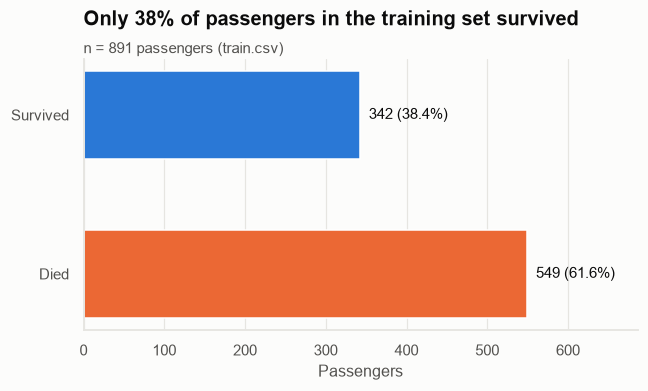

In [9]:
eda.plot_survival_overview(train);

💡 **Insight:** 342 of 891 survived (**38.4%**). The classes are imbalanced (62/38), so any model must beat ~62% just to improve on "everyone died", and **78.7%** to improve on "all women survive".

#### ❓ What did the passenger list look like?

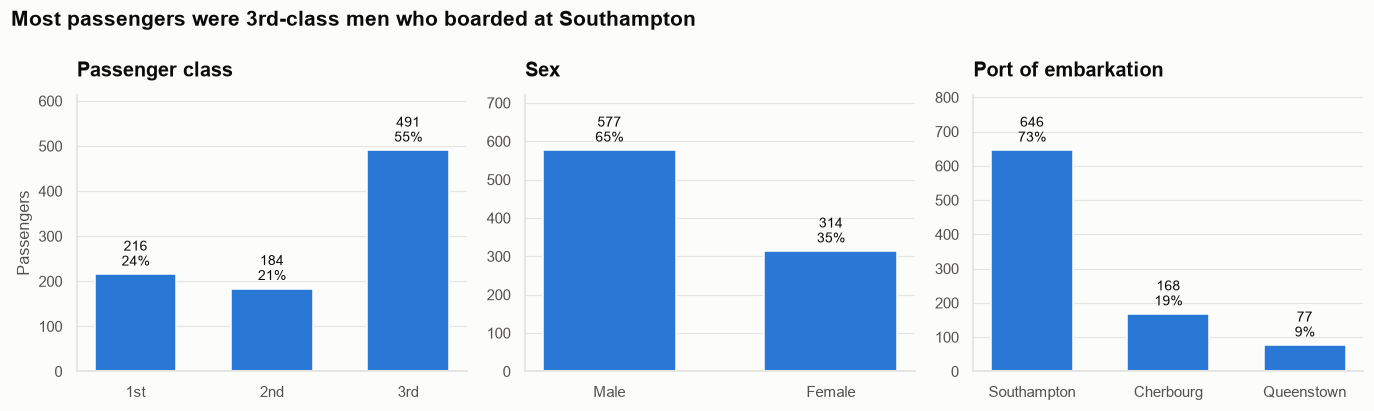

In [10]:
eda.plot_categorical_distributions(train);

💡 **Insight:** 55% of passengers were in **3rd class**, 65% were **male**, and 72% boarded at **Southampton**. Keep this in mind: groups with many passengers dominate the overall survival rate.

#### ❓ What was the age profile?

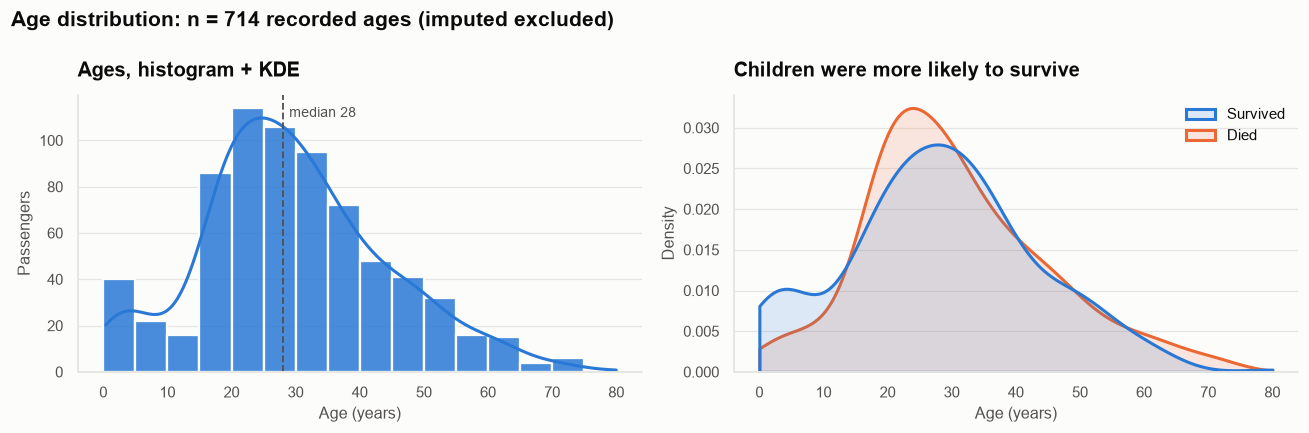

In [11]:
eda.plot_age_distribution(train);

💡 **Insight:** The ship was young (median **28**), mostly 18–40. The densities by outcome overlap almost everywhere **except under ~12**, where survivors clearly outnumber the dead. That is the first sign of "children first". (Only the 714 recorded ages are plotted; imputed ages are excluded so group medians don't create false spikes.)

#### ❓ How were fares distributed?

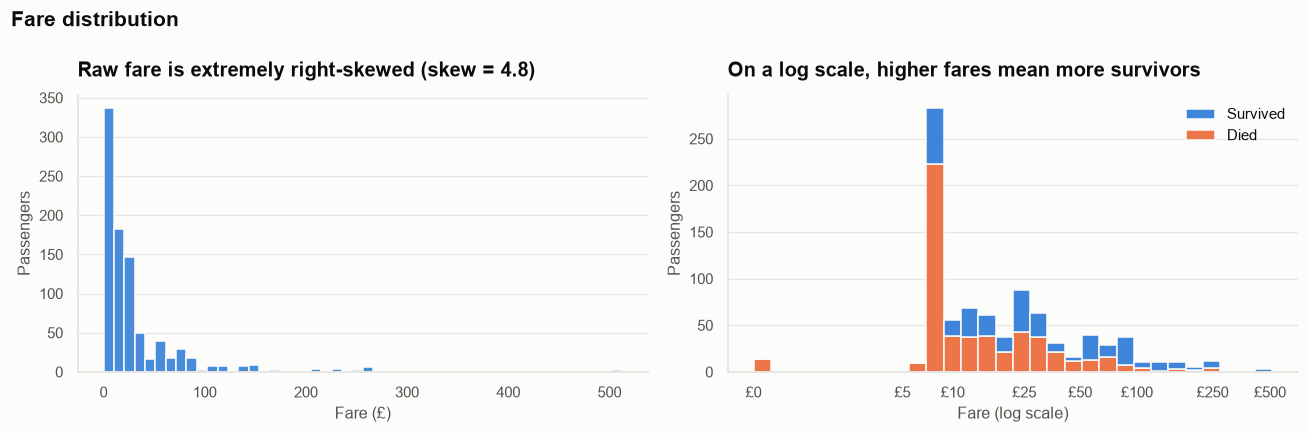

In [12]:
eda.plot_fare_distribution(train);

💡 **Insight:** Fare is extremely skewed (skew ≈ 4.8; median £14.45, max £512). On a log scale the pattern is clear: below ~£10 most passengers died, while above ~£50 most survived.

### 4.2 Bivariate: what was survival linked to?

#### ❓ Did "women and children first" actually hold for women?

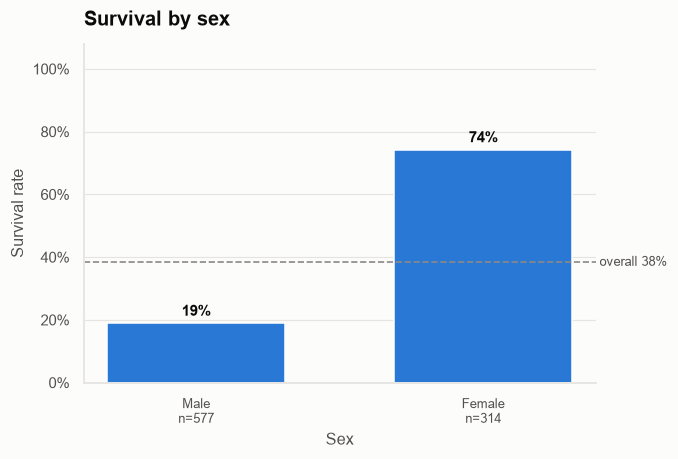

In [13]:
eda.plot_survival_by(train, "Sex");

💡 **Insight:** Yes, clearly. **74%** of women survived against **19%** of men, making sex the single strongest factor in the dataset.

#### ❓ Did class matter?

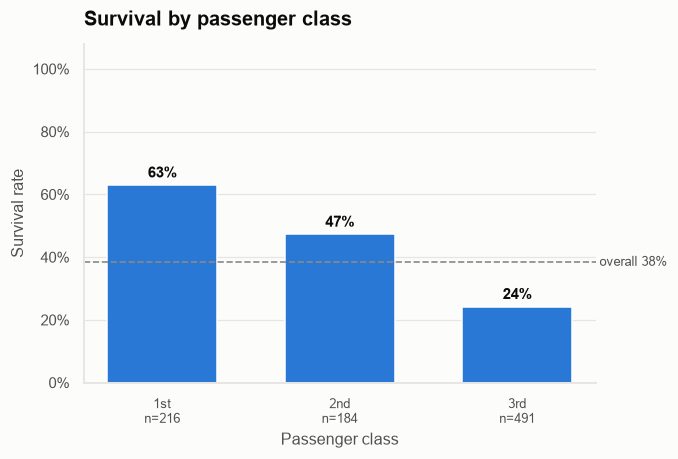

In [14]:
eda.plot_survival_by(train, "Pclass");

💡 **Insight:** Survival falls steadily with class: **63% → 47% → 24%**. 1st-class cabins were closer to the boat deck, and 3rd-class passengers faced longer routes up from the lower decks.

#### ❓ Were children really saved first?

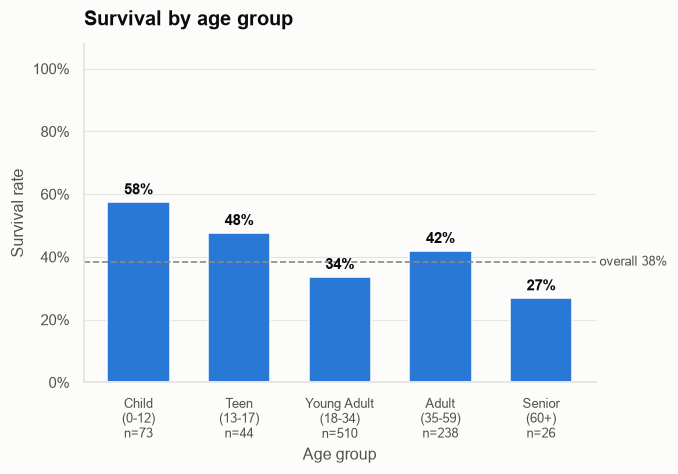

In [15]:
eda.plot_survival_by(train, "AgeGroup");

💡 **Insight:** Children (0–12) survived at **58%**, well above average, while seniors (60+) had the lowest rate at **27%**. The effect is **non-linear**: survival drops from childhood to young adulthood, rises a little for 35–59, then falls again. That's why a simple comparison of mean age misses most of it (see the tests in §5).

#### ❓ Does the port of embarkation matter?

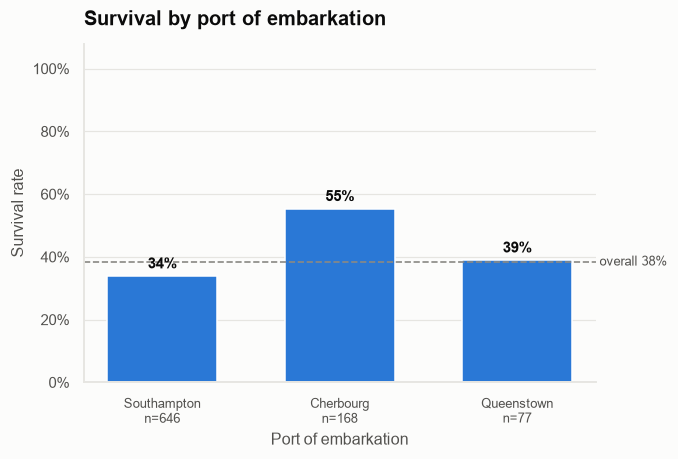

In [16]:
eda.plot_survival_by(train, "Embarked");

In [17]:
pd.crosstab(train["Embarked"], train["Pclass"], normalize="index").round(2).rename(
    columns={1: "1st", 2: "2nd", 3: "3rd"}).assign(survival_rate=train.groupby("Embarked", observed=True)["Survived"].mean().round(2))

Pclass,1st,2nd,3rd,survival_rate
Embarked,,,,
S,0.20,0.25,0.55,0.34
C,0.51,0.10,0.39,0.55
Q,0.03,0.04,0.94,0.39


💡 **Insight:** Cherbourg passengers survived at **55%**, but that's mostly a **class effect**: 51% of Cherbourg passengers were in 1st class, compared with 20% from Southampton and 3% from Queenstown. The port itself didn't save anyone. This is a textbook confounder.

#### ❓ What does a passenger's title reveal?

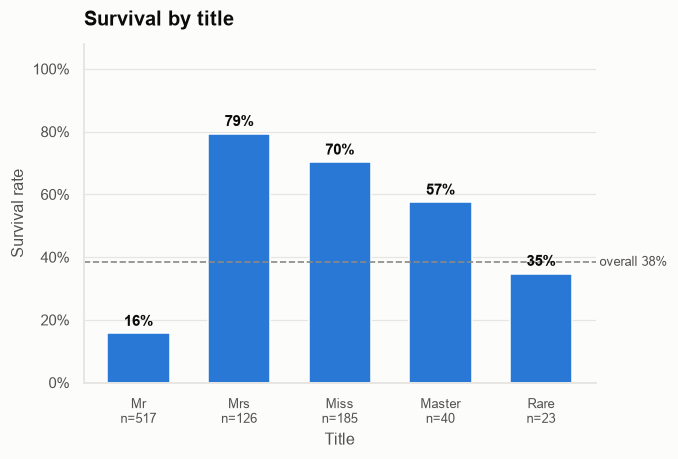

In [18]:
eda.plot_survival_by(train, "Title");

💡 **Insight:** Title combines sex, age and status. **Mrs 79%**, **Miss 70%**, **Master (boys) 57%**, while **Mr only 16%**. "Master" is the interesting one: boys survived at nearly 4× the rate of adult men.

#### ❓ Did travelling with family help?

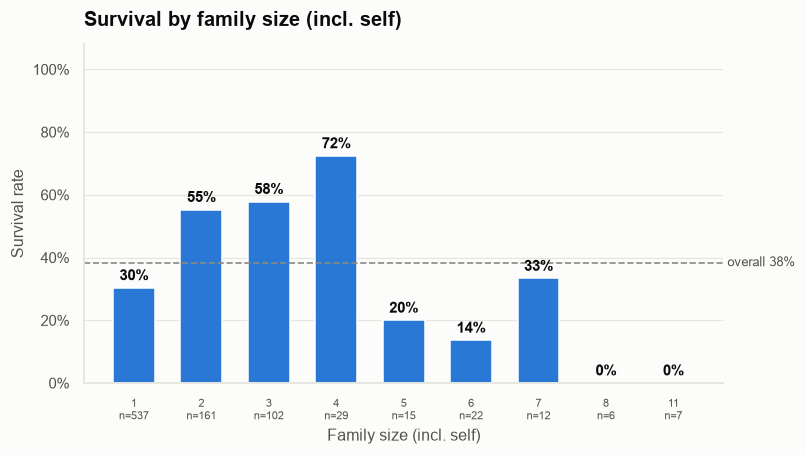

In [19]:
eda.plot_survival_by(train, "FamilySize");

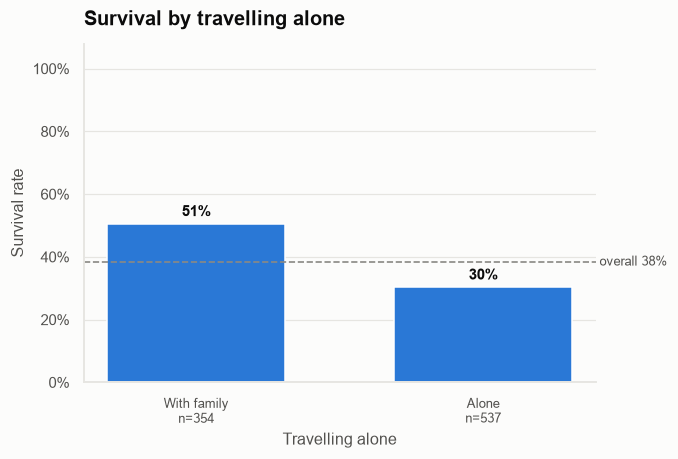

In [20]:
eda.plot_survival_by(train, "IsAlone");

💡 **Insight:** The relationship is **U-shaped**. Solo travellers survived at **30%**, small families (2–4) at **58%** (peaking at 72% for size 4), and large families (5+) at only **16%**. Large families were mostly in 3rd class and hard to keep together. A binary `IsAlone` (51% vs 30%) captures only part of this.

#### ❓ Does the cabin deck matter?

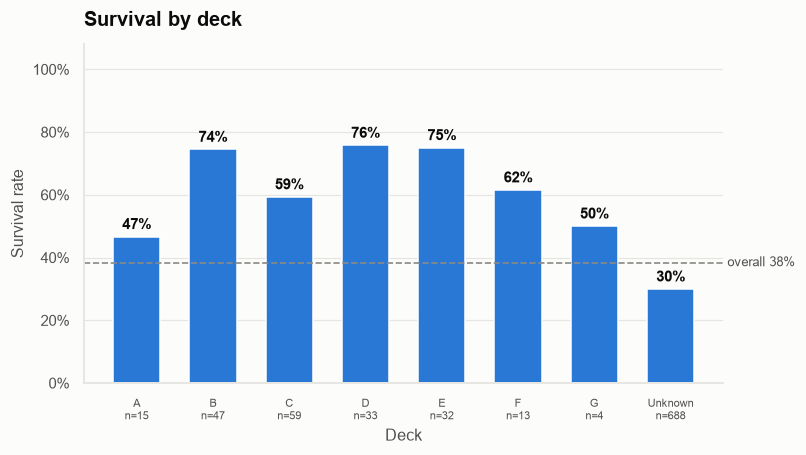

In [21]:
eda.plot_survival_by(train, "Deck");

💡 **Insight:** Passengers with a **recorded cabin survived at 67%**, against **30%** for unknown deck ("U"). But 81% of 1st-class passengers have a recorded cabin compared with 2% in 3rd, so `HasCabin` is largely a proxy for class. Among known decks, B, D and E reach ~75%. Deck G (n=4) is too small to draw conclusions from.

#### The whole picture at once

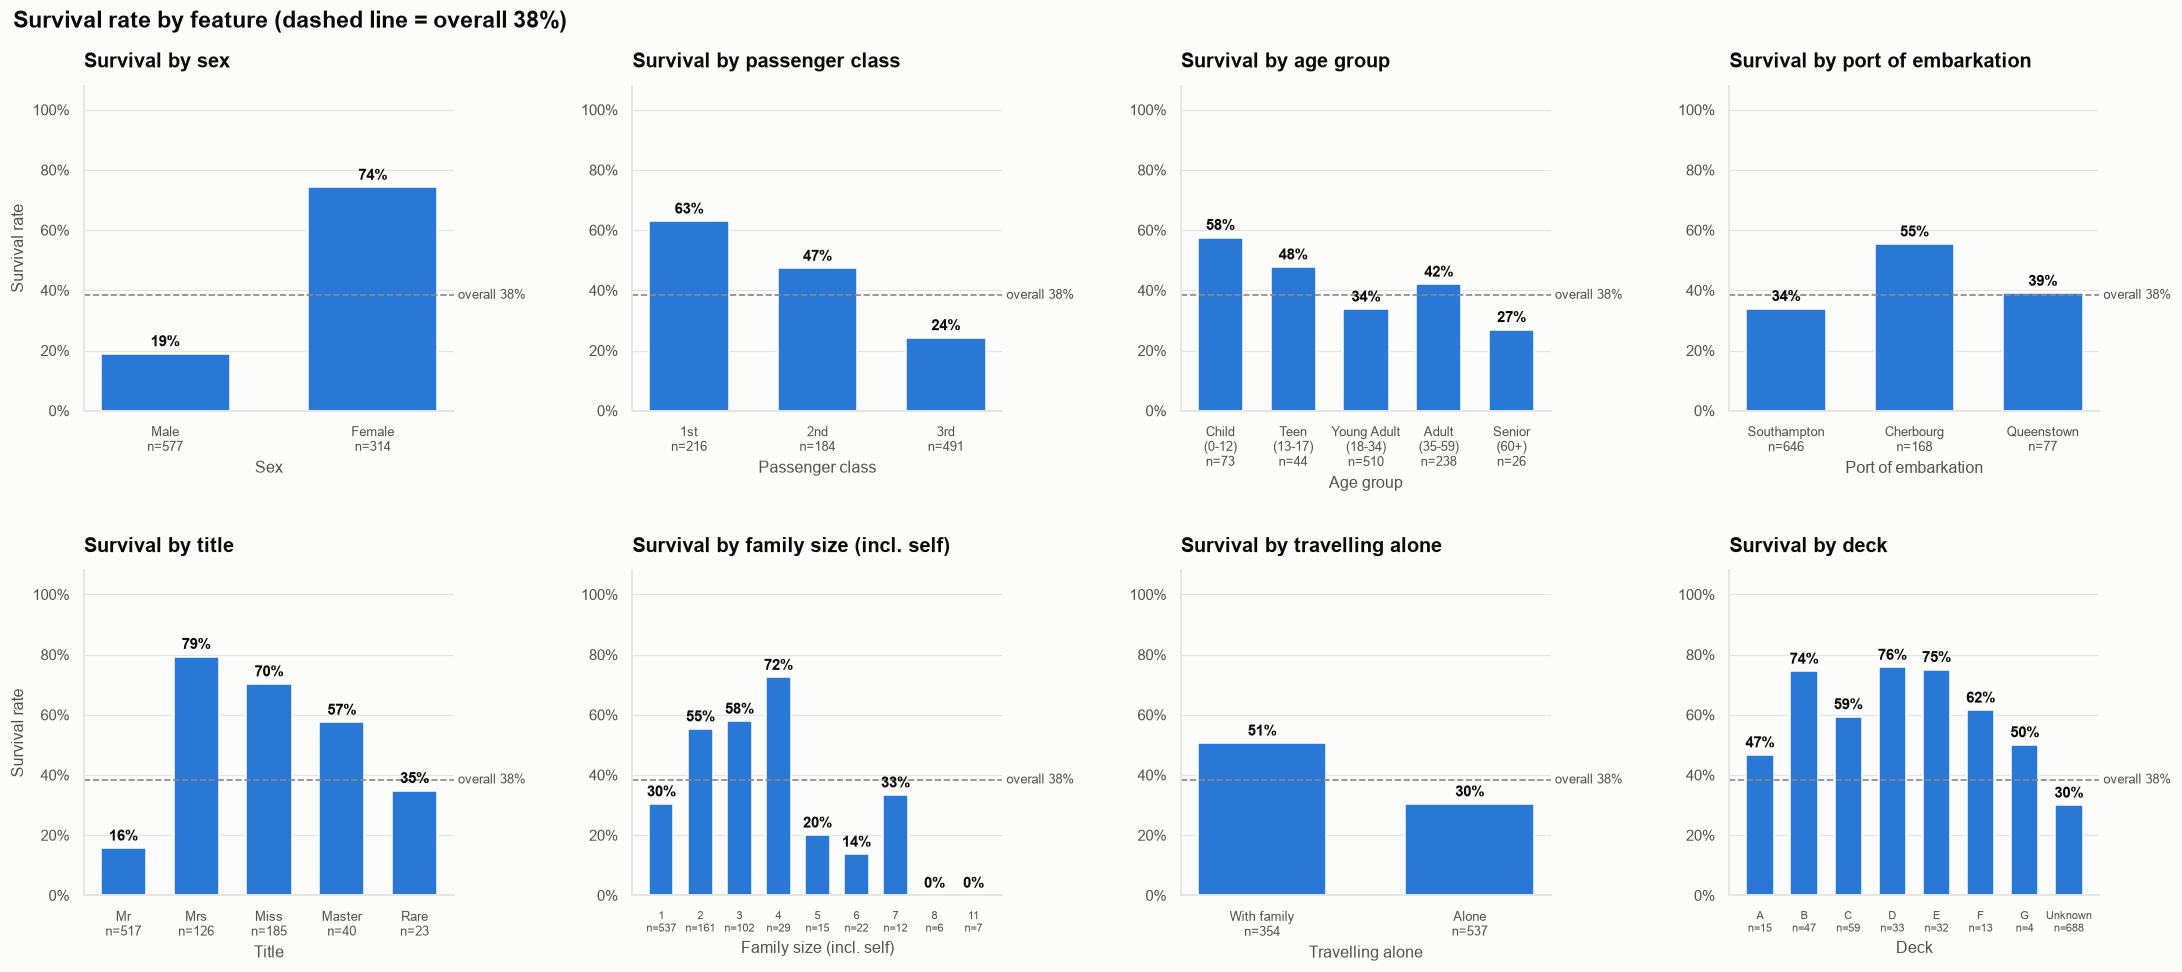

In [22]:
eda.plot_bivariate_grid(train);

### 4.3 Multivariate: how do the factors combine?

#### ❓ How do sex and class interact?

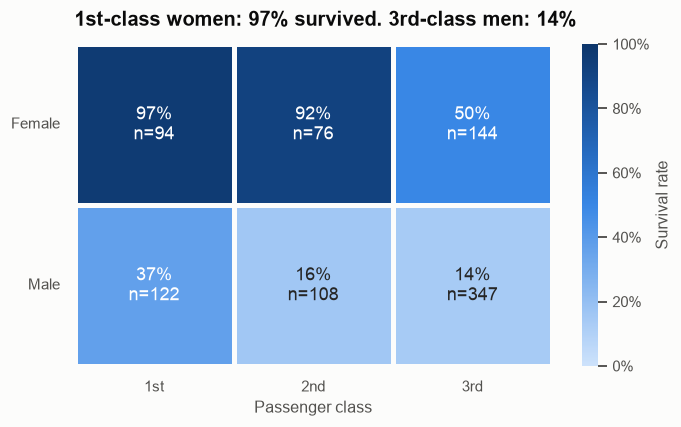

In [23]:
eda.plot_sex_class_heatmap(train);

💡 **Insight:** This is the most important chart in the analysis. **1st-class women survived at 97%** and 2nd-class women at 92%, but **3rd-class women only at 50%**. Among men, 1st class gave 37%, yet 2nd and 3rd class gave just 16% and 14%. A 3rd-class woman still had better odds than a 1st-class man.

#### ❓ Do age and fare together separate survivors?

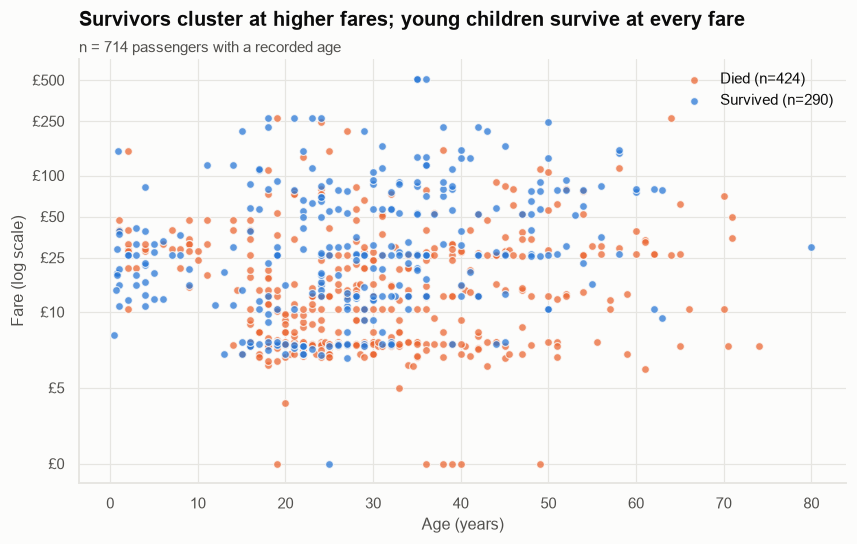

In [24]:
eda.plot_age_fare_scatter(train);

💡 **Insight:** Blue (survived) dominates above ~£50 at every age, and the bottom band (< £10, mostly 3rd class) is overwhelmingly orange. Young children (left edge) survive across all fare levels.

#### ❓ Within each sex and class, how does age play out?

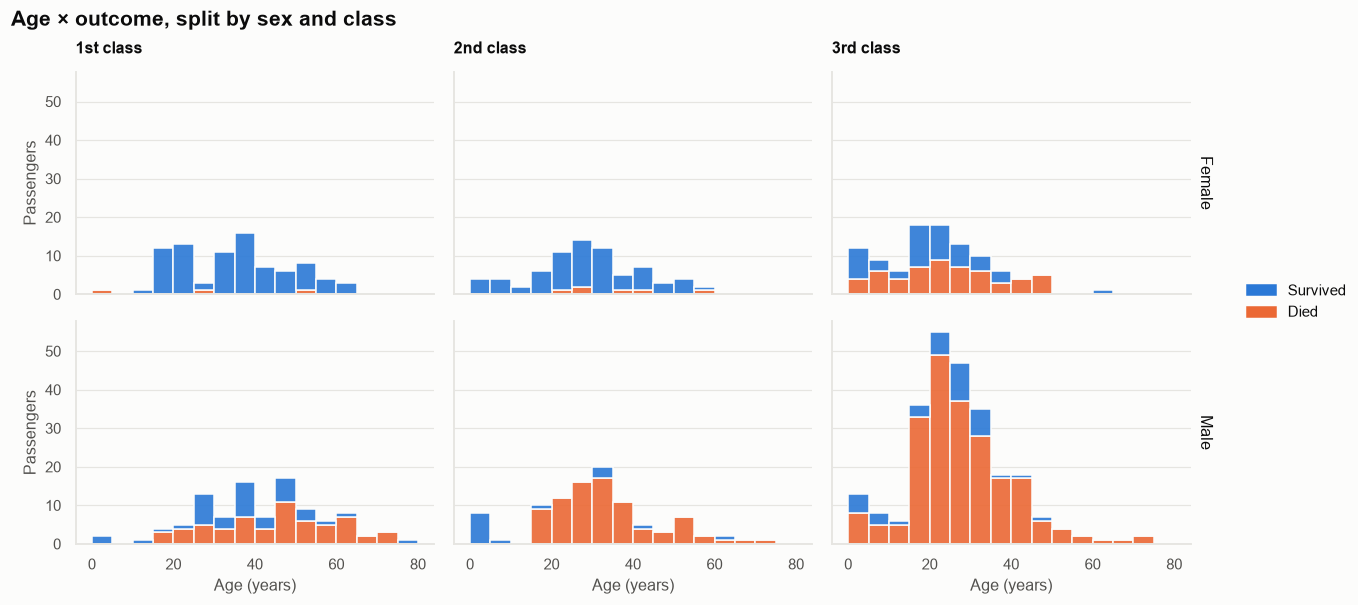

In [25]:
eda.plot_facet_sex_class(train);

💡 **Insight:** 1st- and 2nd-class women survived at almost every age. Among 2nd-class males, **every boy under ~10 survived** while adult men almost all died. In 3rd class, survival is mixed even for children.

In [26]:
masters = train[train["Title"] == "Master"].groupby("Pclass", observed=True)["Survived"].agg(["count", "mean"])
masters.rename(columns={"mean": "survival_rate"}).round(2)

,count,survival_rate
Pclass,,
1,3,1.00
2,9,1.00
3,28,0.39


#### ❓ Which numeric features move together?

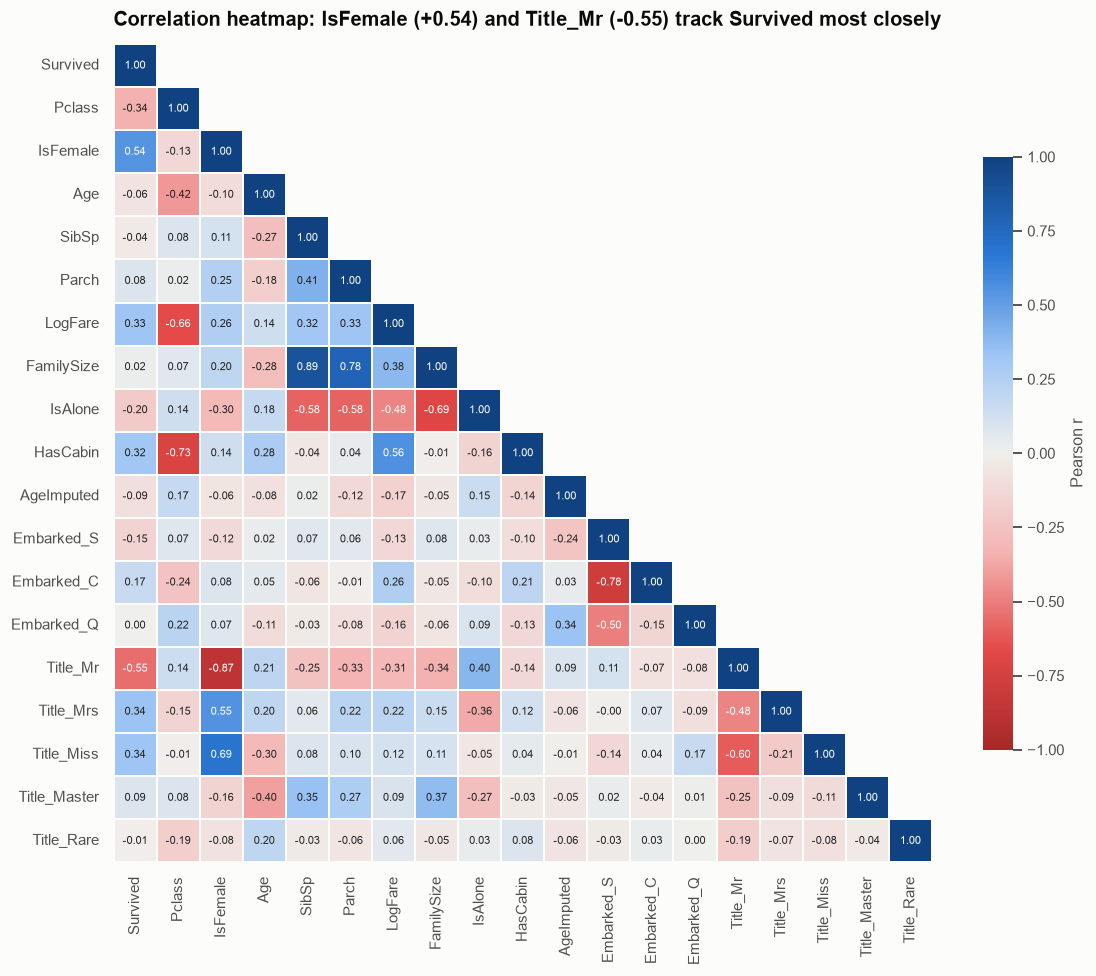

In [27]:
eda.plot_correlation_heatmap(train);

💡 **Insight:**
- **IsFemale (+0.54)** and **Title_Mr (−0.55)** have the strongest correlation with survival, followed by **Pclass (−0.34)**, **LogFare (+0.33)** and **HasCabin (+0.32)**.
- Several features are strongly inter-correlated: Pclass ↔ HasCabin (−0.73) and Pclass ↔ LogFare (−0.66) say that class, fare and cabin all measure the same thing, **wealth**. IsFemale ↔ Title_Mr (−0.87) and FamilySize ↔ SibSp (+0.89) are redundant by construction.
- Raw **Age (−0.06)** barely correlates because its effect isn't linear.

## 5. Statistical tests: is it real or chance?

- **Chi-square test of independence** for each categorical feature against `Survived`, with **Cramér's V** as the effect size (0 = no link, 1 = perfect). With 891 rows even weak links can be "significant", so V shows how *strong* each link is.
- **Welch's t-test** (compares means) and **Mann-Whitney U** (compares distributions by rank, robust to skew) for Age and Fare.

In [28]:
chi = eda.chi_square_tests(train)
num = eda.numeric_tests(train)
eda.save_stats(chi, num)
chi.drop(columns="plain_english").style.format({"p_value": "{:.2e}"}).hide(axis="index")

feature,chi2,dof,p_value,cramers_v,min_expected
Title,288.120000,4,3.96e-61,0.569000,8.800000
Sex,260.720000,1,1.20e-58,0.541000,120.500000
Pclass,102.890000,2,4.55e-23,0.340000,70.600000
Deck,98.780000,7,1.92e-18,0.333000,1.500000
HasCabin,87.940000,1,6.74e-21,0.314000,78.300000
FareBand,80.170000,3,2.82e-17,0.300000,85.200000
FamilyGroup,74.540000,2,6.52e-17,0.289000,23.800000
IsAlone,36.000000,1,1.97e-09,0.201000,135.900000
Embarked,25.960000,2,2.30e-06,0.171000,29.600000
AgeGroup,20.400000,4,4.17e-04,0.151000,10.000000


In [29]:
for line in chi["plain_english"]:
    print("•", line)

• Very strong evidence of a real difference in survival across Title (large effect, V = 0.57).
• Very strong evidence of a real difference in survival across Sex (large effect, V = 0.54).
• Very strong evidence of a real difference in survival across Pclass (medium effect, V = 0.34).
• Very strong evidence of a real difference in survival across Deck (medium effect, V = 0.33). Caution: some expected counts are below 5, so treat this p-value as approximate.
• Very strong evidence of a real difference in survival across HasCabin (medium effect, V = 0.31).
• Very strong evidence of a real difference in survival across FareBand (small effect, V = 0.30).
• Very strong evidence of a real difference in survival across FamilyGroup (small effect, V = 0.29).
• Very strong evidence of a real difference in survival across IsAlone (small effect, V = 0.20).
• Very strong evidence of a real difference in survival across Embarked (small effect, V = 0.17).
• Very strong evidence of a real difference in

In [30]:
display(num.drop(columns="plain_english").style.format({"t_p_value": "{:.2e}", "mw_p_value": "{:.2e}"}).hide(axis="index"))
for line in num["plain_english"]:
    print("•", line)

feature,n,mean_survived,mean_died,median_survived,median_died,welch_t,t_p_value,mann_whitney_u,mw_p_value,rank_biserial_r
Age,714,28.340000,30.630000,28.000000,28.000000,-2.050000,4.12e-02,57682.000000,1.60e-01,-0.062000
Fare,891,48.400000,22.120000,26.000000,10.500000,6.840000,2.70e-11,129951.500000,4.55e-22,0.384000


• Survivors' median Age was 28.0 against 28.0 for those who died (the same median). Mann-Whitney p = 0.16: no significant evidence of a difference (negligible effect, r = -0.06).
• Survivors' median Fare was 26.0 against 10.5 for those who died (higher). Mann-Whitney p = 4.6e-22: very strong evidence of a real difference (medium effect, r = 0.38).


💡 **What the p-values say:**
- **Every categorical feature is significantly associated with survival** (all p < 0.001). The *strength* varies a lot, though: **Title (V = 0.57)** and **Sex (0.54)** are large effects, **Pclass (0.34)** and **Deck (0.33)** are medium, and **Embarked (0.17)** and **AgeGroup (0.15)** are small.
- **Fare:** survivors paid a median of **£26** against **£10.50** for those who died. The chance of a gap this large arising by luck is about 1 in 10²¹.
- **Age:** both groups have a median of **28**. Mann-Whitney finds **no significant difference** (p = 0.16), and the t-test is borderline (p = 0.04). Yet the chi-square test on `AgeGroup` is significant (p = 0.0004). Together these confirm that **age matters only at the extremes**: children did better and seniors worse, which a comparison of averages hides.

## 6. Bonus: do the engineered features help a model?

A quick check rather than a tuned model: Logistic Regression and Random Forest, scored with **stratified 5-fold cross-validation** on the training set. "Raw" uses the original columns only; "engineered" adds Title, FamilySize, IsAlone, HasCabin and Embarked.

Reference: 'all women survive' rule = 78.7%


features,raw,engineered
model,,
Logistic Regression,80.6%,82.9%
Random Forest,83.0%,83.3%


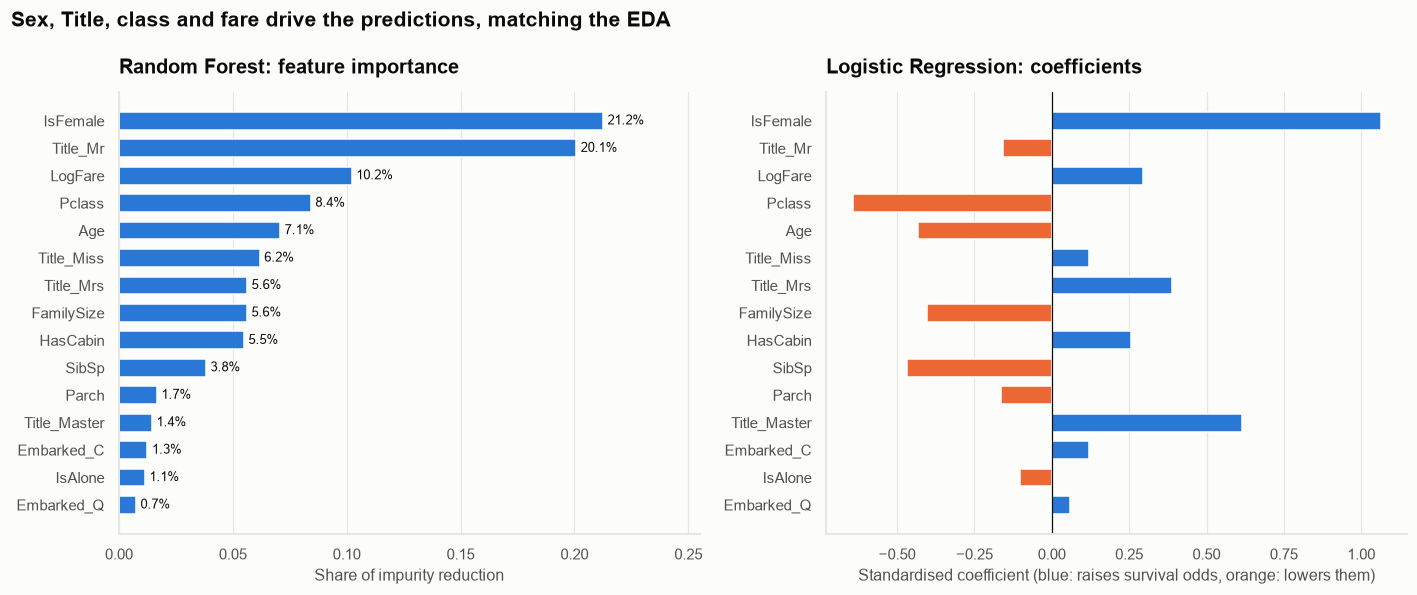

In [31]:
results, importance, rule_acc = model_baseline.run()
print(f"Reference: 'all women survive' rule = {rule_acc:.1%}")
results.pivot(index="model", columns="features", values="cv_accuracy").map("{:.1%}".format)[["raw", "engineered"]]

💡 **Insight:**
- Both models beat the 78.7% "all women survive" rule.
- **Engineered features lift Logistic Regression by ~2.4 points (80.6% → 82.9%)** and make both models more stable across folds. The Random Forest gains less because it can find interactions like sex × class by itself.
- The importance ranking (sex/title → fare → class → age) mirrors the EDA. Because IsFemale overlaps with the Title columns, individual LR coefficients should be read as directions, not exact effect sizes.

## 7. Optional: automated profiling report

`ydata-profiling` can generate an HTML overview. At the time of writing it doesn't support Python 3.14, so this cell skips cleanly if the package is missing (install it on Python ≤ 3.13 to generate `reports/titanic_profile.html`).

In [32]:
try:
    from ydata_profiling import ProfileReport
except ImportError:
    print("ydata-profiling not installed (requires Python < 3.14). Skipping the profiling report.")
else:
    ProfileReport(train, title="Lifeboat Ledger: Titanic Profile", minimal=True).to_file(ROOT / "reports" / "titanic_profile.html")
    print("Saved reports/titanic_profile.html")

ydata-profiling not installed (requires Python < 3.14). Skipping the profiling report.


## 🔑 Key Findings

1. **Only 38.4% survived.** 342 of 891 passengers in the training set.
2. **Sex was the strongest factor.** 74% of women survived against 19% of men (χ² p ≈ 10⁻⁵⁸, Cramér's V = 0.54).
3. **Class created a steep gradient.** 63% in 1st, 47% in 2nd and 24% in 3rd class.
4. **Sex × class tells the full story.** **1st-class women survived at ~97%**, 2nd-class women at 92%, and 3rd-class women at only 50%. 3rd-class men survived at just 14%.
5. **"Children first" was real but limited.** Children under 13 survived at 58% against 34% for young adults. Every boy ("Master") in 1st and 2nd class survived, compared with 39% in 3rd.
6. **Title is the best single feature.** Mrs 79%, Miss 70%, Master 57%, Mr 16% (Cramér's V = 0.57), because it combines sex, age and status.
7. **Money bought survival.** Survivors' median fare was £26 against £10.50 for those who died (Mann-Whitney p ≈ 10⁻²²). The top fare quartile survived at 58%, the bottom at 20%.
8. **Family size is U-shaped.** Small families (2–4) survived at 58%, solo travellers at 30%, and large families (5+) at only 16%.
9. **Cherbourg's 55% is a class illusion.** Half of Cherbourg passengers were in 1st class. Likewise, a recorded cabin (67% survival) mostly signals 1st class.
10. **Average age hides the age effect.** Median age was 28 for both survivors and non-survivors (Mann-Whitney p = 0.16), yet age *groups* differ significantly. The effect lives at the extremes.

**Bonus:** the engineered features push a cross-validated Random Forest to **83.3%** and lift Logistic Regression from 80.6% to **82.9%**, both above the 78.7% "all women survive" rule.